# FFN (Feed Fоrward Network) - нейронные сети прямого распространения

Это полносвязный слой или блок, который преобразует вектор признаков каждого отдельного токена с помощью линейных преобразований и функций активации.

![FFN](https://afit-r.github.io/public/images/analytics/deep_learning/deep_nn.png)

![1](https://encrypted-tbn0.gstatic.com/images?q=tbn:ANd9GcRndfpVEImh-vQaDFMziZMCCyMOPxK1V0vYPkn3wnNAsEb5jK9HEo93qXg&s=10)

FFN реализован в библиотеках и фреймворках для python и часто входит как блок в трансформеры.

Мы будем использовать реализацию из PyTorch


In [ ]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report, r2_score, roc_auc_score, mean_squared_error
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, TensorDataset

In [ ]:
url = "/content/sample_data/california_housing_train.csv"
url_test = "/content/sample_data/california_housing_test.csv"
df = pd.read_csv(url, delimiter=',')

In [ ]:
df.head()

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value
0,-114.31,34.19,15.0,5612.0,1283.0,1015.0,472.0,1.4936,66900.0
1,-114.47,34.40,19.0,7650.0,1901.0,1129.0,463.0,1.8200,80100.0
2,-114.56,33.69,17.0,720.0,174.0,333.0,117.0,1.6509,85700.0
3,-114.57,33.64,14.0,1501.0,337.0,515.0,226.0,3.1917,73400.0
4,-114.57,33.57,20.0,1454.0,326.0,624.0,262.0,1.9250,65500.0


In [ ]:
# Целевая переменная — median_house_value
X = df.drop("median_house_value", axis=1).values.astype(np.float32) # Убираем целевую переменную из Х
y = df["median_house_value"].values.astype(np.float32).reshape(-1, 1) # И добавляем только ее в y

print(f"Размер выборки: {X.shape[0]}, число признаков: {X.shape[1]}")

Размер выборки: 17000, число признаков: 8


In [ ]:
# ------------------------------
# 2. Разбиение на обучающую и тестовую выборки
# ------------------------------
X_train, X_test, y_train, y_test = train_test_split(
  X, y, test_size=0.2, random_state=42
)

In [ ]:
# ------------------------------
# 3. Нормализация признаков и целевой переменной
# ------------------------------
scaler_X = StandardScaler()
X_train = scaler_X.fit_transform(X_train)
X_test = scaler_X.transform(X_test)

scaler_y = StandardScaler()
y_train = scaler_y.fit_transform(y_train)   # теперь y имеет среднее 0, дисперсию 1
y_test = scaler_y.transform(y_test)

In [ ]:
# ------------------------------
# 4. Преобразование в тензоры PyTorch (многомерный массив чисел)
# ------------------------------
X_train_t = torch.tensor(X_train, dtype=torch.float32)
y_train_t = torch.tensor(y_train, dtype=torch.float32)
X_test_t = torch.tensor(X_test, dtype=torch.float32)
y_test_t = torch.tensor(y_test, dtype=torch.float32)

In [ ]:
# ------------------------------
# 5. Создание DataLoader (подача батчами)
# ------------------------------
batch_size = 64
train_dataset = TensorDataset(X_train_t, y_train_t)
test_dataset = TensorDataset(X_test_t, y_test_t)

train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)
test_loader = DataLoader(test_dataset, batch_size=batch_size, shuffle=False)
# DataLoader — это инструмент PyTorch, который упаковывает наши данные и
# позволяет подавать их в модель порциями (батчами) во время обучения.
# Вместо того чтобы передавать сразу все данные (что может не влезть в память),
# мы разбиваем их на маленькие группы.

In [ ]:
# ------------------------------
# 6. Определение модели FFN
# ------------------------------
class HousingFFN(nn.Module):
  def __init__(self, input_dim):
    super().__init__()
    self.fc1 = nn.Linear(input_dim, 128) # Первый линейный слой. Берёт 8 чисел из входного слоя и превращает их в 128 чисел.
    self.fc2 = nn.Linear(128, 64) # Второй слой. Берёт 128 чисел из первого слоя и превращает их в 64 числа.
    self.fc3 = nn.Linear(64, 1) # Линейный  слой (выход). Берёт 64 числа и превращает их в одно число — это и будет предсказание цены дома (пока что в нормализованном виде).
    self.relu = nn.ReLU() # Функция активации ReLU. Она простую вещь: все отрицательные числа превращает в 0, а положительные оставляет как есть. Это добавляет нелинейность, чтобы сеть могла выучить сложные зависимости.
    self.dropout = nn.Dropout(0.2) # Слой «выключения» (Dropout). Во время обучения он случайным образом обнуляет 20% нейронов в предыдущем слое. Борется с переобучением

  def forward(self, x):
    x = self.relu(self.fc1(x)) # Пропускаем данные через 1 слой и ReLU
    x = self.dropout(x) # Выполняем Dropout
    x = self.relu(self.fc2(x)) # Пропускаем данные через 2 слой и ReLU
    x = self.fc3(x)            # Линейный выход (для регрессии)
    return x

device = torch.device("cuda" if torch.cuda.is_available() else "cpu") # Определяемся, где будет выполняться наш код - на GPU или на CPU
model = HousingFFN(X_train.shape[1]).to(device)

In [ ]:
# ------------------------------
# 7. Функция потерь и оптимизатор
# ------------------------------
criterion = nn.MSELoss() # среднеквадратичная ошибка MSE = среднее ((предсказание - реальное значение)^2)
optimizer = optim.Adam(model.parameters(), lr=0.001) # optimizer - это алгоритм, который обновляет веса (параметры) нашей модели, чтобы уменьшить значение функции потерь.
# lr=0.001 — это шаг обучения (learning rate), то есть размер «шага», на который мы корректируем веса при каждом обновлении.

In [ ]:
# ------------------------------
# 8. Цикл обучения
# ------------------------------
epochs = 100
train_losses = []
test_losses = []

for epoch in range(epochs):
  # --- Обучение ---
  model.train()
  running_loss = 0.0 # Обнуляем градиенты перед новым батчем. PyTorch по умолчанию накапливает градиенты (суммирует их), но нам нужно, чтобы каждый батч давал независимую оценку.
  for X_batch, y_batch in train_loader:
    X_batch, y_batch = X_batch.to(device), y_batch.to(device)
    optimizer.zero_grad()
    outputs = model(X_batch) # Подаём батч на вход модели — получаем предсказания (нормализованные цены домов)
    loss = criterion(outputs, y_batch) # Вычисляем ошибку: сравниваем предсказания с правильными ответами с помощью MSELoss. Получаем одно число (скаляр)
    loss.backward() # Обратное распространение ошибки
    optimizer.step() # Оптимизатор делает шаг: обновляет веса модели в направлении уменьшения ошибки с учётом learning rate
    running_loss += loss.item() * X_batch.size(0) # Складываем в running_loss для всей эпохи
  epoch_train_loss = running_loss / len(train_loader.dataset) # Получаем среднюю ошибку за эпоху
  train_losses.append(epoch_train_loss) # Сохраняем это значение, чтобы потом его проанализировать

  # --- Валидация на тесте ---
  model.eval()
  val_loss = 0.0
  with torch.no_grad(): # На тесте градиенты не считаем
    for X_batch, y_batch in test_loader:
      X_batch, y_batch = X_batch.to(device), y_batch.to(device)
      outputs = model(X_batch)
      loss = criterion(outputs, y_batch)
      val_loss += loss.item() * X_batch.size(0)
  epoch_test_loss = val_loss / len(test_loader.dataset) # Получаем среднюю ошибку за эпоху на тестовых жанных
  test_losses.append(epoch_test_loss) # Сохраняем тестовые ошибки, чтобы потом его проанализировать его с тренировочным

  if (epoch + 1) % 20 == 0:
      print(f"Epoch {epoch+1}/{epochs} — Train Loss: {epoch_train_loss:.6f}, Test Loss: {epoch_test_loss:.6f}")

Epoch 20/100 — Train Loss: 0.175677, Test Loss: 0.191102
Epoch 40/100 — Train Loss: 0.172890, Test Loss: 0.187219
Epoch 60/100 — Train Loss: 0.168039, Test Loss: 0.189907
Epoch 80/100 — Train Loss: 0.163238, Test Loss: 0.188772
Epoch 100/100 — Train Loss: 0.162075, Test Loss: 0.188257


In [ ]:
# Валидация на тесте
model.eval()
val_loss = 0.0
with torch.no_grad():
  for X_batch, y_batch in test_loader:
    X_batch, y_batch = X_batch.to(device), y_batch.to(device)
    outputs = model(X_batch)
    loss = criterion(outputs, y_batch)
    val_loss += loss.item() * X_batch.size(0)
epoch_test_loss = val_loss / len(test_loader.dataset)
test_losses.append(epoch_test_loss)

if (epoch+1) % 20 == 0:
  print(f"Epoch {epoch+1}/{epochs} — Train Loss: {epoch_train_loss:.6f}, Test Loss: {epoch_test_loss:.6f}")

Epoch 100/100 — Train Loss: 0.162075, Test Loss: 0.188257


In [ ]:
# ------------------------------
# 9. Оценка модели в исходном масштабе цен
# ------------------------------
model.eval()
y_pred_scaled = []
y_true_scaled = []

with torch.no_grad():
  for X_batch, y_batch in test_loader:
    X_batch = X_batch.to(device)
    preds = model(X_batch)
    y_pred_scaled.extend(preds.cpu().numpy().flatten())
    y_true_scaled.extend(y_batch.numpy().flatten())

In [ ]:
# Обратное масштабирование
y_pred = scaler_y.inverse_transform(np.array(y_pred_scaled).reshape(-1, 1))
y_true = scaler_y.inverse_transform(np.array(y_true_scaled).reshape(-1, 1))

mse = mean_squared_error(y_true, y_pred)
r2 = r2_score(y_true, y_pred)

print("\n" + "="*50)
print("Оценка модели на тестовой выборке (в исходных ценах):")
print("="*50)
print(f"Среднеквадратичная ошибка (MSE): {mse:.2f}")
print(f"Коэффициент детерминации (R²):  {r2:.4f}")


Оценка модели на тестовой выборке (в исходных ценах):
Среднеквадратичная ошибка (MSE): 2516593152.00
Коэффициент детерминации (R²):  0.8174


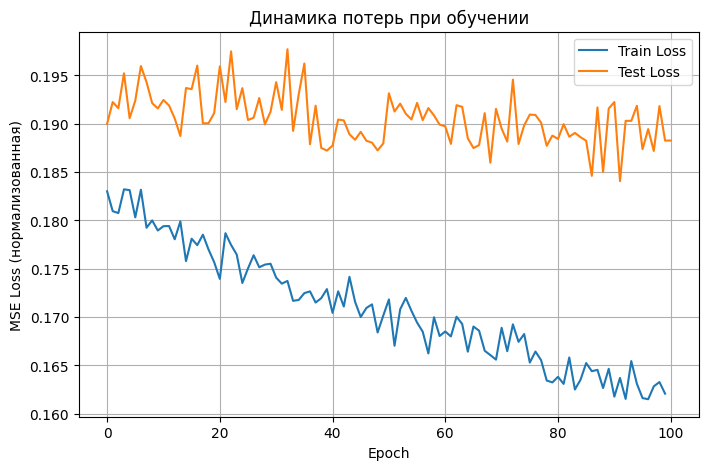

In [ ]:
# ------------------------------
# 10. График потерь
# ------------------------------
plt.figure(figsize=(8, 5))
plt.plot(train_losses, label='Train Loss')
plt.plot(test_losses, label='Test Loss')
plt.xlabel('Epoch')
plt.ylabel('MSE Loss (нормализованная)')
plt.title('Динамика потерь при обучении')
plt.legend()
plt.grid(True)
plt.show()


# Задача классификации


In [ ]:
import numpy as np
import pandas as pd
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, confusion_matrix

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, TensorDataset

In [ ]:
# ===================== 1. Загрузка данных =====================
data = load_breast_cancer()
X = data.data.astype(np.float32)
y = data.target.astype(np.float32).reshape(-1, 1)

print(f"Признаков: {X.shape[1]}, Объектов: {X.shape[0]}")
print(f"Классы: 0 = {data.target_names[0]}, 1 = {data.target_names[1]}")

Признаков: 30, Объектов: 569
Классы: 0 = malignant, 1 = benign


In [ ]:
# ===================== 2. Разбиение на train/test =====================
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

In [ ]:

# ===================== 3. Нормализация признаков =====================
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

In [ ]:
# ===================== 4. Преобразование в тензоры =====================
X_train_t = torch.tensor(X_train)
y_train_t = torch.tensor(y_train)
X_test_t = torch.tensor(X_test)
y_test_t = torch.tensor(y_test)

In [ ]:
# ===================== 5. DataLoader =====================
batch_size = 32
train_dataset = TensorDataset(X_train_t, y_train_t)
test_dataset = TensorDataset(X_test_t, y_test_t)

train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)
test_loader = DataLoader(test_dataset, batch_size=batch_size, shuffle=False)

In [ ]:
# ===================== 6. Определение модели FFN =====================
class BreastCancerFFN(nn.Module):
  def __init__(self, input_dim):
    super().__init__()
    self.fc1 = nn.Linear(input_dim, 64)
    self.fc2 = nn.Linear(64, 32)
    self.fc3 = nn.Linear(32, 1) # Для бинарной классификации достаточно одного выхода: если логит > 0, то класс 1, иначе — 0.
    self.relu = nn.ReLU()
    self.dropout = nn.Dropout(0.2)

  def forward(self, x):
    x = self.relu(self.fc1(x))
    x = self.dropout(x)
    x = self.relu(self.fc2(x))
    x = self.fc3(x)          # линейный выход (logits)
    return x

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model = BreastCancerFFN(X_train.shape[1]).to(device)

In [ ]:
# ===================== 7. Функция потерь и оптимизатор =====================
criterion = nn.BCEWithLogitsLoss()   # устойчивая комбинация Sigmoid + BCELoss
optimizer = optim.Adam(model.parameters(), lr=0.001)

In [ ]:
# ===================== 8. Цикл обучения =====================
epochs = 100
train_losses, test_losses = [], []

for epoch in range(epochs):
    # --- Train ---
    model.train()
    running_loss = 0.0
    for X_batch, y_batch in train_loader:
        X_batch, y_batch = X_batch.to(device), y_batch.to(device)
        optimizer.zero_grad()
        outputs = model(X_batch)
        loss = criterion(outputs, y_batch)
        loss.backward()
        optimizer.step()
        running_loss += loss.item() * X_batch.size(0)
    epoch_train_loss = running_loss / len(train_loader.dataset)
    train_losses.append(epoch_train_loss)

    # --- Validation ---
    model.eval()
    val_loss = 0.0
    with torch.no_grad():
        for X_batch, y_batch in test_loader:
            X_batch, y_batch = X_batch.to(device), y_batch.to(device)
            outputs = model(X_batch)
            loss = criterion(outputs, y_batch)
            val_loss += loss.item() * X_batch.size(0)
    epoch_test_loss = val_loss / len(test_loader.dataset)
    test_losses.append(epoch_test_loss)

    if (epoch + 1) % 20 == 0:
        print(f"Epoch {epoch+1}/{epochs} — Train Loss: {epoch_train_loss:.4f}, Test Loss: {epoch_test_loss:.4f}")


Epoch 20/100 — Train Loss: 0.0361, Test Loss: 0.0937
Epoch 40/100 — Train Loss: 0.0144, Test Loss: 0.1093
Epoch 60/100 — Train Loss: 0.0063, Test Loss: 0.1245
Epoch 80/100 — Train Loss: 0.0081, Test Loss: 0.1634
Epoch 100/100 — Train Loss: 0.0023, Test Loss: 0.1658


In [ ]:
# ===================== 9. Оценка модели =====================
model.eval()
y_pred_prob = []
y_true = []

with torch.no_grad():
    for X_batch, y_batch in test_loader:
        X_batch = X_batch.to(device)
        outputs = model(X_batch)
        probs = torch.sigmoid(outputs)          # вероятность класса 1
        y_pred_prob.extend(probs.cpu().numpy().flatten())
        y_true.extend(y_batch.numpy().flatten())

y_pred_prob = np.array(y_pred_prob)
y_true = np.array(y_true)
y_pred_class = (y_pred_prob >= 0.5).astype(int)


In [ ]:
# ===================== 10. Метрики =====================
# Accuracy — доля правильных ответов
# Precision — из всех предсказанных положительных, сколько действительно положительных
# Recall — из всех реальных положительных, сколько мы нашли
# F1-score — гармоническое среднее между Precision и Recall (полезно при дисбалансе)
# ROC-AUC — площадь под ROC-кривой; показывает, насколько хорошо модель разделяет классы (0.5 — случайно, 1.0 — идеально)

print("\n" + "="*50)
print("Оценка на тестовой выборке:")
print("="*50)
print(f"Accuracy:  {accuracy_score(y_true, y_pred_class):.4f}")
print(f"Precision: {precision_score(y_true, y_pred_class):.4f}")
print(f"Recall:    {recall_score(y_true, y_pred_class):.4f}")
print(f"F1-score:  {f1_score(y_true, y_pred_class):.4f}")
print(f"ROC-AUC:   {roc_auc_score(y_true, y_pred_prob):.4f}")
print("\nConfusion Matrix:")
print(confusion_matrix(y_true, y_pred_class))


Оценка на тестовой выборке:
Accuracy:  0.9561
Precision: 0.9855
Recall:    0.9444
F1-score:  0.9645
ROC-AUC:   0.9924

Confusion Matrix:
[[41  1]
 [ 4 68]]


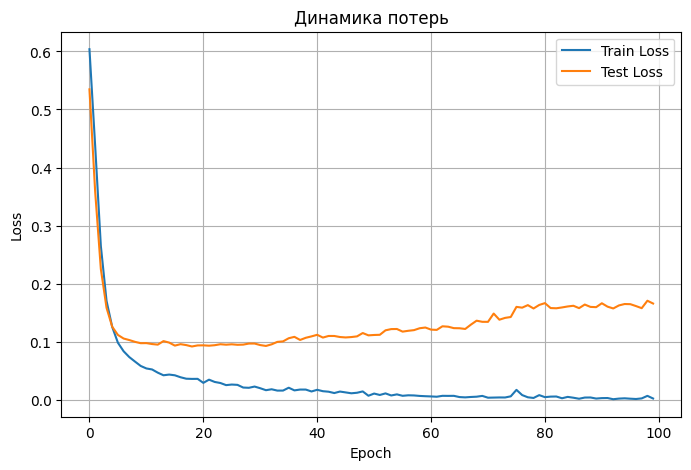

In [ ]:
# ===================== 11. График потерь =====================
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))
plt.plot(train_losses, label='Train Loss')
plt.plot(test_losses, label='Test Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.title('Динамика потерь')
plt.legend()
plt.grid(True)
plt.show()